In [154]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
import warnings
warnings.simplefilter("ignore")
%matplotlib inline

sns.set(style="darkgrid")

In [155]:
data = pd.read_csv("winequality-red.csv", sep=";")
data.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [156]:
# size + типы данных
display(data.shape) 
data.info()

(1599, 12)

<class 'pandas.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB


In [157]:
display(data["quality"].describe())

count    1599.000000
mean        5.636023
std         0.807569
min         3.000000
25%         5.000000
50%         6.000000
75%         6.000000
max         8.000000
Name: quality, dtype: float64

In [158]:
data.columns

Index(['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar',
       'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density',
       'pH', 'sulphates', 'alcohol', 'quality'],
      dtype='str')

In [159]:
print('Количество пропусков в столбцах:\n', data.isnull().sum())

Количество пропусков в столбцах:
 fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64


In [160]:
from sklearn.model_selection import train_test_split

#data = data.drop(columns=["Id"])

y = data["quality"]
X = data.drop(columns=["quality"])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
# стандарт 20/80
# при random_state=42 всегда одинаковое разделение
# проблема - переобучение

<Axes: xlabel='quality', ylabel='Count'>

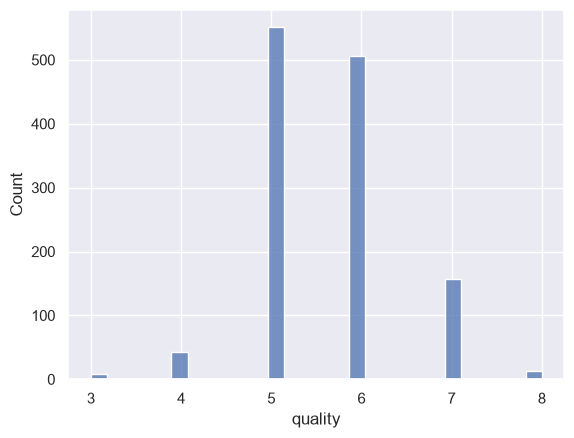

In [161]:
# распределение по целевой 
sns.histplot(y_train)

ВЫВОДЫ: 

Распределение целевой переменной сдвинуто к средним значениям (5 и 6).
Экстремально низкие или высокие оценки (3, 4, 7, 8) встречаются гораздо реже,
что может осложнить их предсказание моделью.

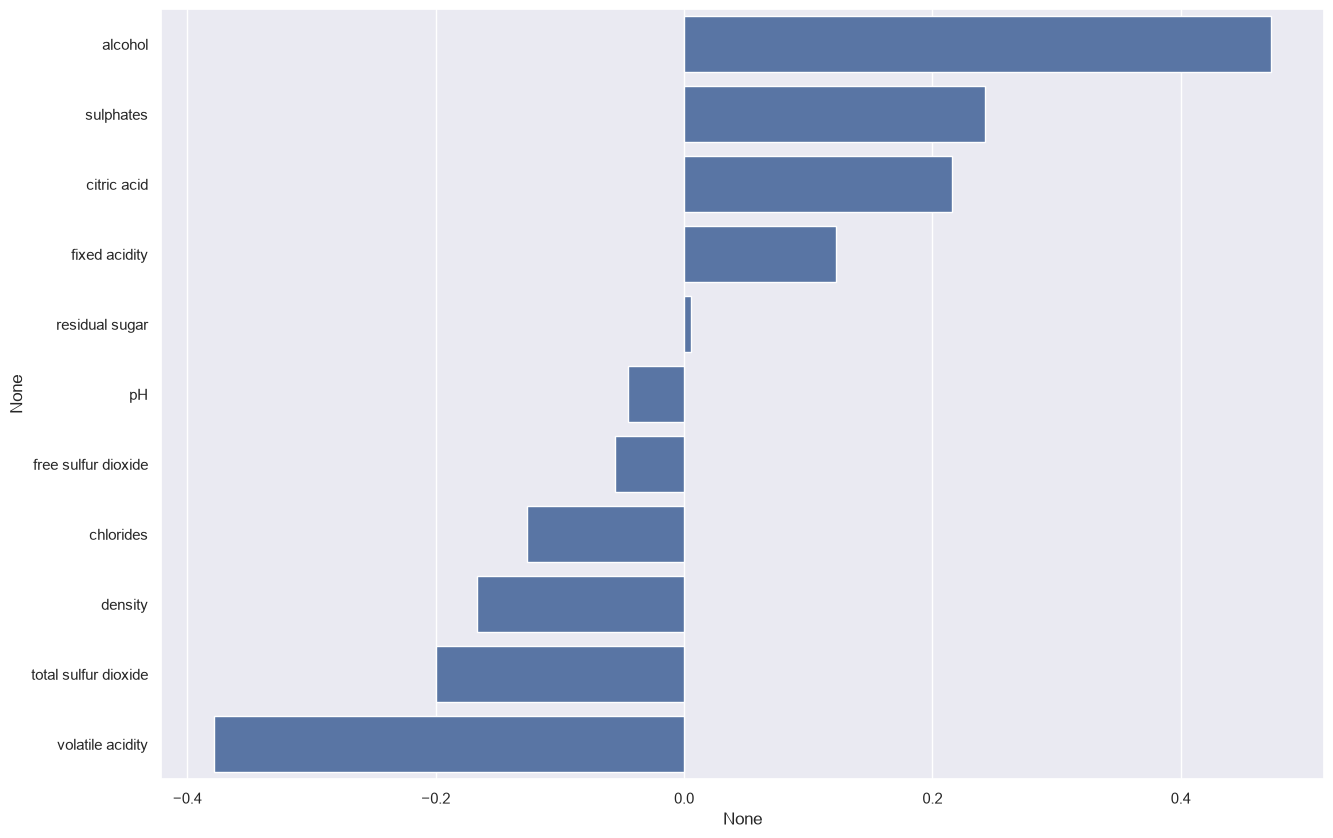

In [162]:
# корреляция каждого признака с целевой
# без отбора - data.info() показал, что все признаки числовые
correlations = X_train.corrwith(y_train).sort_values(ascending=False)

plot = sns.barplot(y=correlations.index, x=correlations)
plot.figure.set_size_inches(15, 10)

+1 — идеальная положительная связь (чем больше признак, тем больше качество).

-1 — идеальная отрицательная связь (чем больше признак, тем меньше качество).

0 — связи нет вообще.

ВЫВОДЫ: 

Положительная связь: сильнее всего на повышение качества влияет alcohol.

Отрицательная связь: сильнее всего качество портит volatile acidity (летучая кислотность).

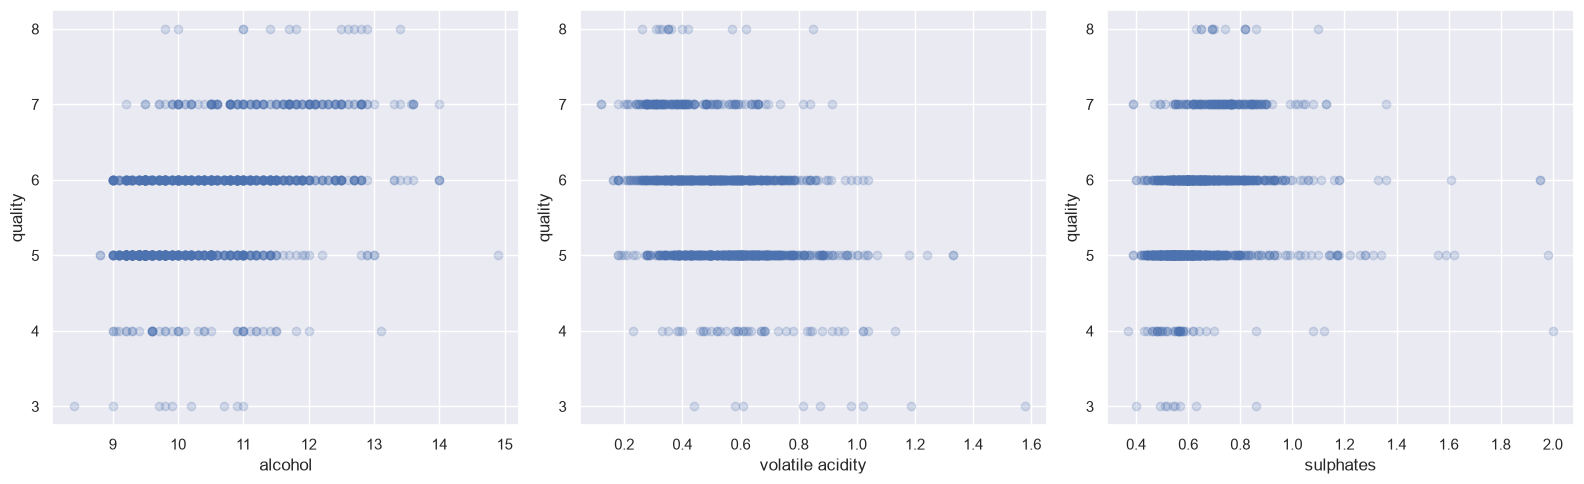

In [163]:
fig, axs = plt.subplots(figsize=(16, 5), ncols=3)

for i, feature in enumerate(["alcohol", "volatile acidity", "sulphates"]):
    axs[i].scatter(X_train[feature], y_train, alpha=0.2)
    axs[i].set_xlabel(feature)
    axs[i].set_ylabel("quality")
    
plt.tight_layout()

In [164]:
# Baseline не использует признаки
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

baseline_prediction = y_train.mean()  # предсказание константой
y_pred = np.full_like(y_test, baseline_prediction)

rmse_Baseline = root_mean_squared_error(y_test, y_pred)
mae_Baseline = mean_absolute_error(y_test, y_pred)

print(f"Baseline RMSE = {rmse_Baseline:.4f}")
print(f"Baseline MAE = {mae_Baseline:.4f}")

Baseline RMSE = 1.0592
Baseline MAE = 0.7594


ВЫВОДЫ:

Что показывает MAE (Mean Absolute Error):
Среднюю абсолютную ошибку. Отражает среднее отклонение предсказаний модели в единицах целевой переменной. Все ошибки учитываются одинаково. (сумма модулей разницы между тем, что предсказала модель, и тем, что было на самом деле, делится на их кол-во)

Что показывает RMSE (Root Mean Squared Error):
Корень из среднеквадратичной ошибки. Сильнее реагирует на крупные ошибки.

Почему RMSE сильнее реагирует на большие ошибки:
Перед извлечением корня ошибки возводятся в квадрат.

Почему для одной и той же модели значения MAE и RMSE могут заметно различаться:
RMSE всегда больше или равна MAE. Из-за возведения в квадрат, чем больше крупных ошибок, тем сильнее RMSE будет превышать MAE.

In [165]:
# ЛИНЕЙНАЯ РЕГРЕССИЯ
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler() # масштабируем
# scaler.fit из значения признака вычетает среднее и делит на среднеквадратичное отклонение(разброс)
X_train_sc = scaler.fit_transform(X_train) 
X_test_sc = scaler.transform(X_test)

model_1LR = LinearRegression()
model_1LR.fit(X_train_sc, y_train)
y_pred_lr = model_1LR.predict(X_test_sc)

rmse_LR = root_mean_squared_error(y_test, y_pred_lr)
mae_LR = mean_absolute_error(y_test, y_pred_lr)

print(f"Linear Regression RMSE = {rmse_LR:.4f}")
print(f"Baseline RMSE = {rmse_Baseline:.4f}")
print("--------------------------------------")
print(f"Linear Regression MAE = {mae_LR:.4f}")
print(f"Baseline MAE = {mae_Baseline:.4f}")

coeff = pd.DataFrame(
    {"Признак": X_train.columns, "Коэффициент": model_1LR.coef_}
)
coeff["Влияние"] = coeff["Коэффициент"].abs()
coeff = coeff.sort_values(by="Влияние", ascending=False)
display(coeff)

Linear Regression RMSE = 0.6245
Baseline RMSE = 1.0592
--------------------------------------
Linear Regression MAE = 0.5035
Baseline MAE = 0.7594


,Признак,Коэффициент,Влияние
10,alcohol,0.296628,0.296628
1,volatile acidity,-0.179439,0.179439
9,sulphates,0.146815,0.146815
6,total sulfur dioxide,-0.120008,0.120008
4,chlorides,-0.089084,0.089084
8,pH,-0.060610,0.060610
5,free sulfur dioxide,0.058015,0.058015
0,fixed acidity,0.039789,0.039789
2,citric acid,-0.027512,0.027512
7,density,-0.019204,0.019204


ВЫВОДЫ:

Метрики линейной регрессии ниже метрик Baseline, следовательно: модель работает лучше базового усреднения.

Наибольшее влияние оказывают признаки: alcohol, sulphates, volatile acidity.

StandardScaler масштабирует признаки, поэтому мы можем корректно сравнить влияние признаков на качество.(масштабировали, потому что признаки меняются в разных диапазонах)

In [166]:
# Random Forest Regressor
from sklearn.ensemble import RandomForestRegressor

model_2RF = RandomForestRegressor(random_state=42) #  закрепили случайность, чтобы было одинаковое разделение
model_2RF.fit(X_train, y_train) # масштабирование не нужно
y_pred_rf = model_2RF.predict(X_test)

rmse_rf = root_mean_squared_error(y_test, y_pred_rf)
mae_rf = mean_absolute_error(y_test, y_pred_rf)

print(f"Random Forest RMSE = {rmse_rf:.4f}")
print(f"Baseline RMSE = {rmse_Baseline:.4f}")
print("--------------------------------------")
print(f"Random Forest MAE = {mae_rf:.4f}")
print(f"Baseline MAE = {mae_Baseline:.4f}")

feature_importance2 = pd.DataFrame(
    {"Признак": X_train.columns, "Важность": model_2RF.feature_importances_}
)
feature_importance2 = feature_importance2.sort_values(by="Важность", ascending=False)
display(feature_importance2)

Random Forest RMSE = 0.5489
Baseline RMSE = 1.0592
--------------------------------------
Random Forest MAE = 0.4224
Baseline MAE = 0.7594


,Признак,Важность
10,alcohol,0.270868
9,sulphates,0.148406
1,volatile acidity,0.111547
6,total sulfur dioxide,0.076786
4,chlorides,0.071132
8,pH,0.061418
3,residual sugar,0.057892
0,fixed acidity,0.053186
7,density,0.050816
2,citric acid,0.050752


ВЫВОДЫ:

Метрики Random Forest Regressor ниже метрик Baseline, следовательно: модель работает лучше базового усреднения.

Метрики Random Forest Regressor ниже метрик Линейной регрессии, так как учитывает нелинейные связи.

Наибольшее влияние оказывают признаки: alcohol, sulphates, volatile acidity.

Не масштабируем признаки, так как идем по алгоритму деревьев решений - на основе сравнений значений признаков.

In [168]:
# Gradient Boosting Regressor
from sklearn.ensemble import GradientBoostingRegressor

model_3GB = GradientBoostingRegressor(random_state=42,)

model_3GB.fit(X_train, y_train)
y_pred_gb = model_3GB.predict(X_test)

rmse_gb = root_mean_squared_error(y_test, y_pred_gb)
mae_gb = mean_absolute_error(y_test, y_pred_gb)

#y_q = model_3GB.predict(X_train)
#mae_q = mean_absolute_error(y_train, y_q)
#print(f"mae for train = {mae_q:.4f}")
# 0.3873

print("--------------------------------------")
print(f"Gradient Boosting RMSE = {rmse_gb:.4f}")
print(f"Random Forest RMSE = {rmse_rf:.4f}")
print(f"Baseline RMSE = {rmse_Baseline:.4f}")
print("--------------------------------------")
print(f"Gradient Boosting MAE = {mae_gb:.4f}")
print(f"Random Forest MAE = {mae_rf:.4f}")
print(f"Baseline MAE = {mae_Baseline:.4f}")

feature_importance3 = pd.DataFrame(
    {"Признак": X_train.columns, "Важность": model_3GB.feature_importances_}
)
feature_importance3 = feature_importance3.sort_values(by="Важность", ascending=False)
display(feature_importance3)

--------------------------------------
Gradient Boosting RMSE = 0.6019
Random Forest RMSE = 0.5489
Baseline RMSE = 1.0592
--------------------------------------
Gradient Boosting MAE = 0.4849
Random Forest MAE = 0.4224
Baseline MAE = 0.7594


,Признак,Важность
10,alcohol,0.375965
9,sulphates,0.194299
1,volatile acidity,0.125359
6,total sulfur dioxide,0.075183
0,fixed acidity,0.056945
4,chlorides,0.039518
8,pH,0.033658
3,residual sugar,0.030401
7,density,0.028772
2,citric acid,0.020073


ВЫВОДЫ:

Метрики Gradient Boosting Regressor ниже метрик Baseline, следовательно: модель работает лучше базового усреднения.

Метрики Gradient Boosting Regressor ниже метрик Линейной регрессии, так как учитывает нелинейные связи.

Метрики Gradient Boosting Regressor выше метрик Random Forest Regressor, так как на данном .

Наибольшее влияние оказывают признаки: alcohol, sulphates, volatile acidity.

Не масштабируем признаки, так как идем по алгоритму деревьев решений - на основе сравнений значений признаков.